# Logistic Regression and Feature Selection on Colon Cancer Data

**Objective.** Build a reproducible binary classification workflow for colon cancer tissue status using gene-expression features, logistic regression, coefficient-based feature importance, and reduced-feature retraining.


## Reproducibility and Environment

Fixed random seeds, deterministic train/test splitting, and explicit preprocessing are used throughout the analysis.


In [1]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 42
TEST_SIZE = 0.20

np.random.seed(RANDOM_STATE)
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="viridis",
    rc={
        "figure.figsize": (10, 6),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
    },
)


## 1. Dataset Loading and Initial Inspection


The dataset is loaded with explicit semicolon parsing. The workflow supports execution in Google Colab after uploading `colon_cancer.csv`.


In [3]:
DATA_CANDIDATES = [
    Path("/content/colon_cancer.csv"),
    Path("/content/colon_cancer 6.csv"),
    Path("colon_cancer.csv"),
    Path("colon_cancer 6.csv"),
]

def locate_dataset(candidates):
    for candidate in candidates:
        if candidate.exists():
            return candidate

    try:
        from google.colab import files

        display(Markdown("Upload `colon_cancer.csv` to continue."))
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("No file was uploaded.")
        return Path(next(iter(uploaded.keys())))
    except ModuleNotFoundError as exc:
        raise FileNotFoundError(
            "Dataset not found. Place colon_cancer.csv in the working directory or upload it in Colab."
        ) from exc

DATA_PATH = locate_dataset(DATA_CANDIDATES)
df = pd.read_csv(DATA_PATH, sep=";")

print(f"Dataset path: {DATA_PATH}")
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")


Upload `colon_cancer.csv` to continue.

Saving colon_cancer 6.csv to colon_cancer 6.csv
Dataset path: colon_cancer 6.csv
Dataset shape: 804 rows x 62 columns


In [4]:
display(df.head())


,id_sample,ADH1C,DHRS11,UGP2,SLC7A5,CTSS,DAO,NIBAN1,PRUNE2,FOXF2,...,BSPRY,CDHR2,ERRFI1,CLIC5,PLLP,GAL,CRYL1,YBX2,ANGPTL4,tissue_status
0,EPSM-COLON-0001,9.199944,6.090054,7.062512,3.864253,7.869368,8.465133,1.174665,0.975086,3.028995,...,5.528372,3.500730,2.893760,5.130743,1.485110,1.830484,6.379933,3.919293,3.031413,normal
1,EPSM-COLON-0002,7.767618,6.027985,6.318818,3.069581,6.410334,8.159814,5.959414,1.625518,2.984629,...,5.671788,4.658790,4.715374,5.438104,2.131466,2.097157,6.863173,0.322829,3.978531,normal
2,EPSM-COLON-0003,7.918904,5.885948,6.917742,3.188257,7.915549,8.004194,1.560386,2.379909,2.929762,...,4.596079,5.649376,4.047899,6.580938,1.447209,3.890943,6.209704,3.274407,3.714491,normal
3,EPSM-COLON-0004,9.053553,6.027985,7.081085,2.357523,5.657726,8.004194,3.548988,3.260031,3.313829,...,4.135061,5.437107,4.537381,4.615263,1.004454,1.840902,6.774063,3.320525,3.080796,normal
4,EPSM-COLON-0005,6.027822,5.791257,5.937685,4.137667,5.818999,8.056067,3.307945,5.208874,4.191695,...,3.674043,6.286182,4.715374,4.432410,0.159195,3.506561,6.150297,0.461184,5.140305,normal


In [5]:
variable_summary = (
    pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_rate": df.isna().mean(),
        "unique_values": df.nunique(dropna=True),
    })
    .sort_values(["missing_rate", "unique_values"], ascending=[False, True])
)

display(variable_summary)


,dtype,missing,missing_rate,unique_values
tissue_status,object,0,0.0,2
PLA2G12B,float64,0,0.0,521
DAO,float64,0,0.0,554
RPSAP19,float64,0,0.0,558
IGLV8-61,float64,0,0.0,574
...,...,...,...,...
SIDT1,float64,0,0.0,601
YBX2,float64,0,0.0,601
NIBAN1,float64,0,0.0,603
ANKRD40CL,float64,0,0.0,603


In [6]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_sample,804,804,EPSM-COLON-0804,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ADH1C,804.0,NaN,NaN,NaN,5.588943,2.889901,0.610504,3.17425,5.467024,8.444756,10.263846
DHRS11,804.0,NaN,NaN,NaN,4.354817,1.431179,1.427079,3.118844,4.12599,5.696566,7.022241
UGP2,804.0,NaN,NaN,NaN,5.557694,1.150565,2.027201,4.61106,5.412204,6.556969,7.571114
SLC7A5,804.0,NaN,NaN,NaN,4.51357,1.61445,1.685024,3.030022,4.382953,5.918848,8.05943
...,...,...,...,...,...,...,...,...,...,...,...
GAL,804.0,NaN,NaN,NaN,2.822931,1.338349,0.610504,1.840902,2.591044,3.661012,7.545757
CRYL1,804.0,NaN,NaN,NaN,6.096634,0.840122,2.031471,5.489589,6.150297,6.728052,8.723941
YBX2,804.0,NaN,NaN,NaN,2.801603,1.011971,0.0,2.277491,2.905605,3.505721,5.169059
ANGPTL4,804.0,NaN,NaN,NaN,2.596452,1.000962,0.757246,1.824823,2.442378,3.139738,6.493643


**Inspection note.** The dataset contains sample identifiers, gene-expression measurements, and a binary tissue-status target. Numerical features are treated as continuous predictors.


## 2. Exploratory Data Analysis


### Missing Values Analysis


In [7]:
missing_table = (
    df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_rate=lambda x: x["missing_count"] / len(df))
    .query("missing_count > 0")
    .sort_values("missing_rate", ascending=False)
)

if missing_table.empty:
    display(Markdown("No missing values were detected in the dataset."))
else:
    display(missing_table)


No missing values were detected in the dataset.

In [49]:

missing_counts = df.isna().sum()

missing_columns = missing_counts[missing_counts > 0]

if missing_columns.empty:
    print("The dataset contains no missing values.")
else:
    print("The following variables contain missing values:\n")
    print(missing_columns.sort_values(ascending=False))

The dataset contains no missing values.


In [50]:
if df.isna().values.any():
    print("The dataset contains missing values.")
else:
    print("The dataset contains no missing values.")


The dataset contains no missing values.


### Duplicate Detection


In [10]:
duplicate_rows = df.duplicated().sum()
duplicate_ids = df["id_sample"].duplicated().sum() if "id_sample" in df.columns else np.nan

duplicate_summary = pd.DataFrame(
    {
        "criterion": ["complete rows", "sample identifiers"],
        "duplicate_count": [duplicate_rows, duplicate_ids],
    }
)
display(duplicate_summary)


,criterion,duplicate_count
0,complete rows,0
1,sample identifiers,0


### Target Distribution


In [11]:
target_col = "tissue_status"
target_counts = df[target_col].value_counts().rename_axis("class").reset_index(name="count")
target_counts["proportion"] = target_counts["count"] / target_counts["count"].sum()
display(target_counts)


,class,count,proportion
0,normal,402,0.5
1,tumoral,402,0.5


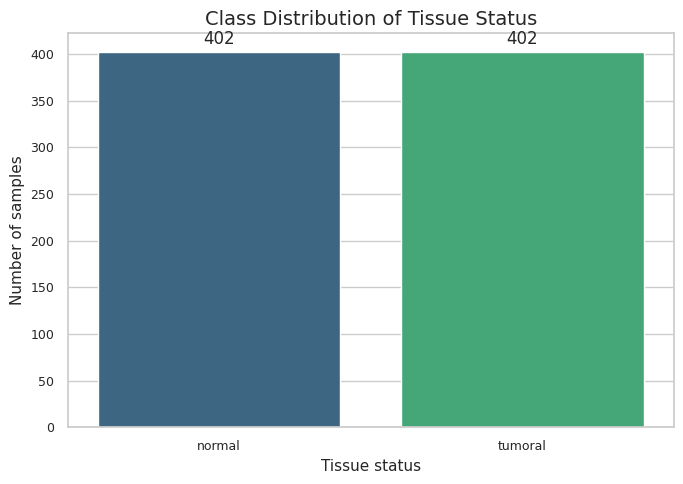

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x=target_col, order=target_counts["class"], ax=ax, palette="viridis")
ax.set_title("Class Distribution of Tissue Status")
ax.set_xlabel("Tissue status")
ax.set_ylabel("Number of samples")

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()


**Interpretation.** Class balance is assessed before modeling because imbalance would affect metric selection and threshold interpretation.


### Feature Distribution Analysis


In [13]:
id_col = "id_sample"
feature_cols = [col for col in df.select_dtypes(include=np.number).columns if col not in [target_col]]

feature_variance = df[feature_cols].var().sort_values(ascending=False)
high_variance_features = feature_variance.head(12).index.tolist()

display(
    pd.DataFrame({
        "feature": high_variance_features,
        "variance": feature_variance.loc[high_variance_features].values,
    })
)


,feature,variance
0,FABP1,9.128160
1,ADH1C,8.351527
2,IGLV8-61,7.387061
3,CDHR2,2.742629
4,SLC7A5,2.606450
5,L1TD1,2.194496
6,RNF43,2.193360
7,NIBAN1,2.151813
8,DHRS11,2.048273
9,DAO,1.993658


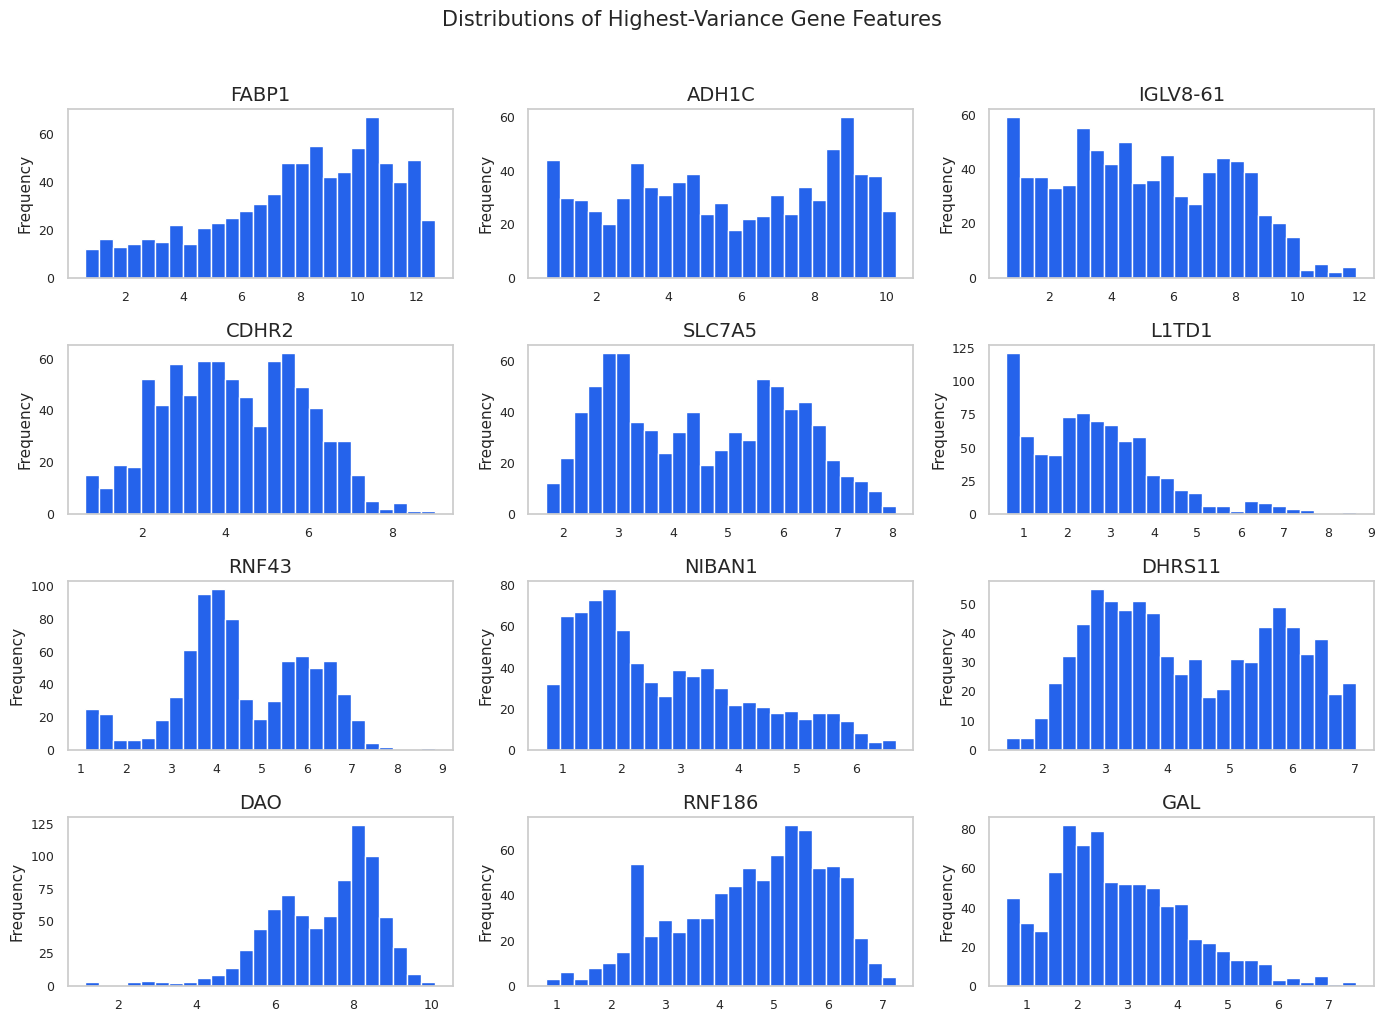

In [14]:
axes = df[high_variance_features].hist(
    bins=25,
    figsize=(14, 10),
    color="#2563EB",
    edgecolor="white",
    grid=False,
)
for ax in axes.ravel():
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")
plt.suptitle("Distributions of Highest-Variance Gene Features", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()


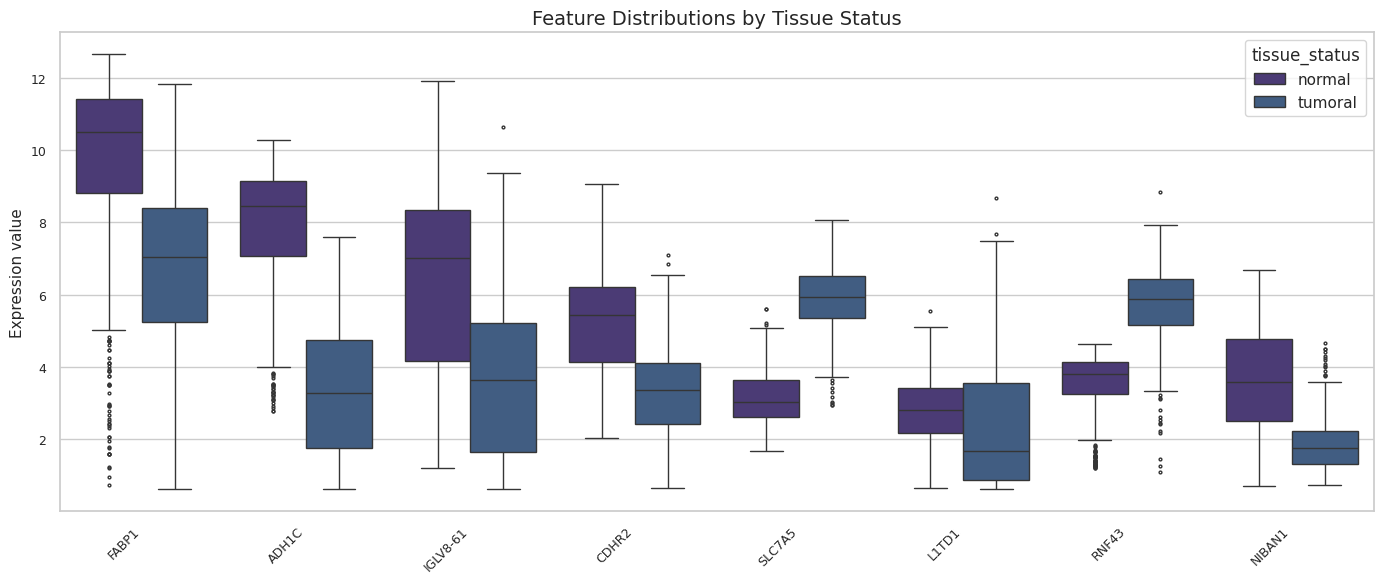

In [15]:
melted_features = df[[target_col] + high_variance_features[:8]].melt(
    id_vars=target_col,
    var_name="feature",
    value_name="expression",
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(
    data=melted_features,
    x="feature",
    y="expression",
    hue=target_col,
    ax=ax,
    fliersize=2,
    linewidth=1,
)
ax.set_title("Feature Distributions by Tissue Status")
ax.set_xlabel("")
ax.set_ylabel("Expression value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Interpretation.** Features with visible class separation in distributional summaries are expected to receive higher discriminatory weight in the logistic model.


### Correlation Analysis


In [16]:
positive_label = "tumoral" if "tumoral" in set(df[target_col].astype(str)) else sorted(df[target_col].astype(str).unique())[-1]
target_binary_for_corr = (df[target_col].astype(str) == positive_label).astype(int)

target_correlations = (
    df[feature_cols]
    .corrwith(target_binary_for_corr)
    .rename("target_correlation")
    .to_frame()
    .assign(abs_correlation=lambda x: x["target_correlation"].abs())
    .sort_values("abs_correlation", ascending=False)
)

top_corr_features = target_correlations.head(20).index.tolist()
display(target_correlations.head(20))


,target_correlation,abs_correlation
UGP2,-0.876723,0.876723
SLC7A5,0.841920,0.841920
NEURL1B,-0.782198,0.782198
ADH1C,-0.769183,0.769183
DAO,-0.765864,0.765864
RNF43,0.724815,0.724815
CLIC5,-0.718637,0.718637
FOXF2,-0.690116,0.690116
DHRS11,-0.683455,0.683455
TENT5C,-0.656736,0.656736


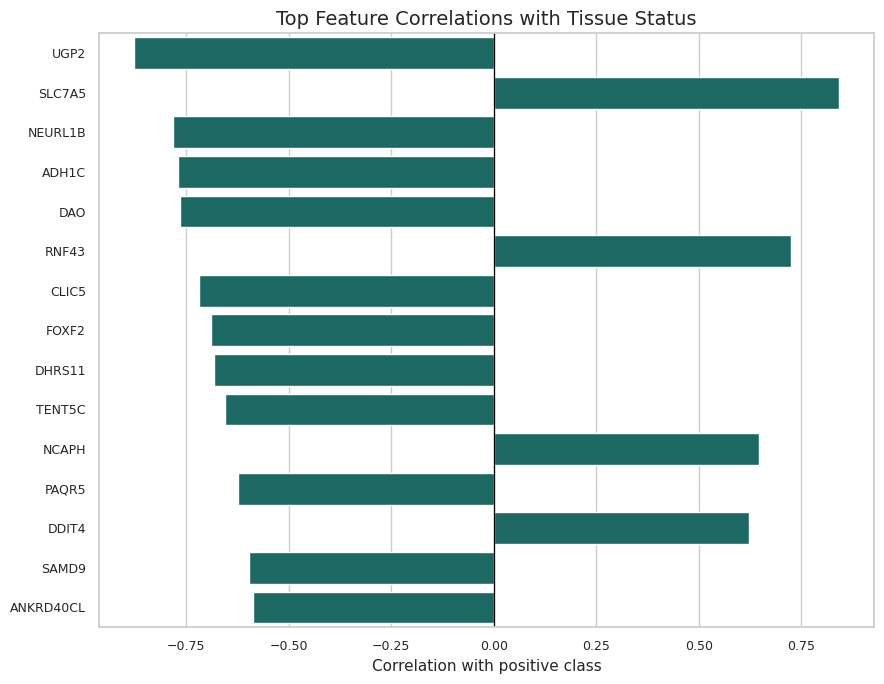

In [17]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(
    data=target_correlations.head(15).reset_index(),
    y="index",
    x="target_correlation",
    color="#0F766E",
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_title("Top Feature Correlations with Tissue Status")
ax.set_xlabel("Correlation with positive class")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


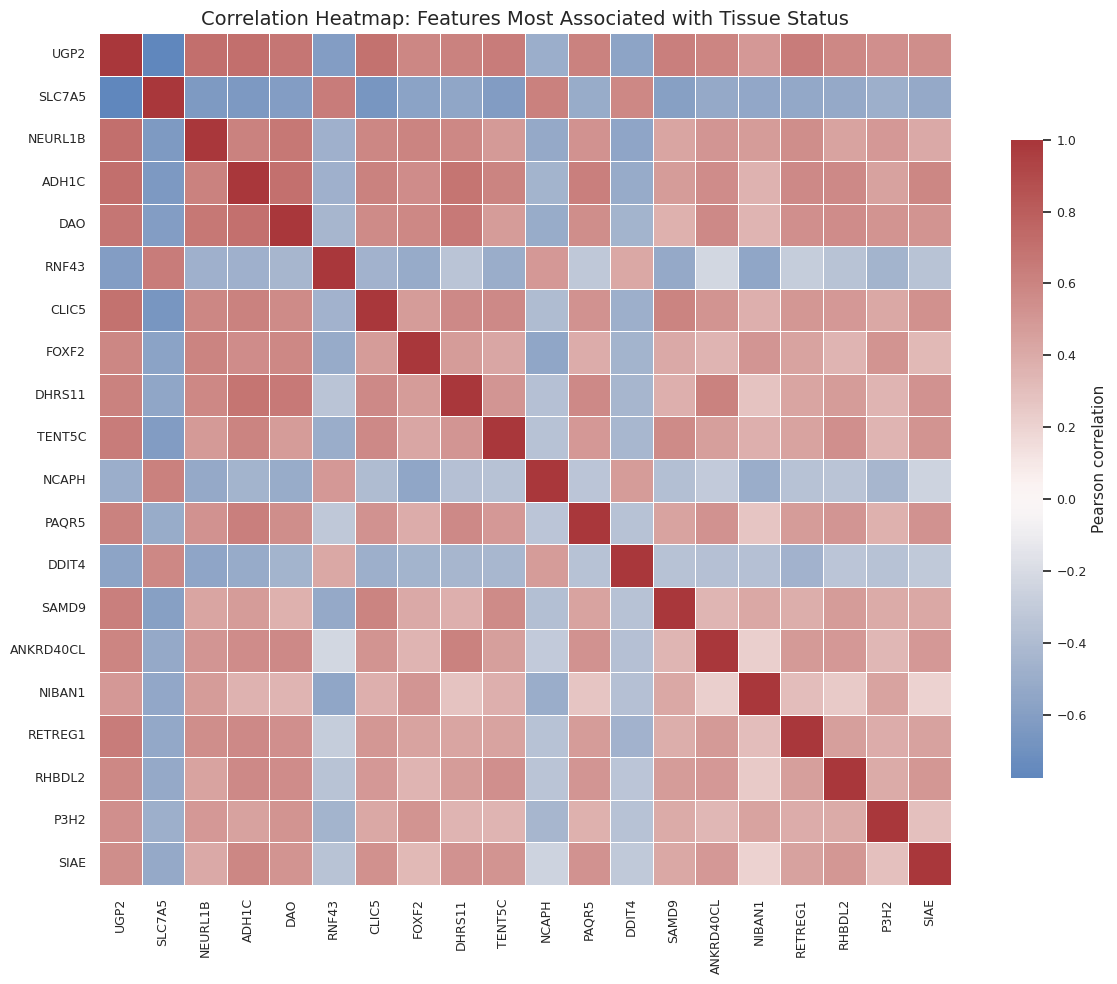

In [18]:
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(
    df[top_corr_features].corr(),
    cmap="vlag",
    center=0,
    linewidths=0.4,
    square=True,
    cbar_kws={"shrink": 0.75, "label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation Heatmap: Features Most Associated with Tissue Status")
plt.tight_layout()
plt.show()


**Interpretation.** Strong feature-feature correlations indicate possible redundancy; this is relevant when interpreting coefficient stability and reduced-feature models.


## 3. Data Preprocessing


In [19]:
negative_label = [label for label in sorted(df[target_col].astype(str).unique()) if label != positive_label][0]

X = df[feature_cols].copy()
y = (df[target_col].astype(str) == positive_label).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

shapes = pd.DataFrame(
    {
        "matrix": ["X", "X_train", "X_test", "y_train", "y_test"],
        "shape": [X.shape, X_train.shape, X_test.shape, y_train.shape, y_test.shape],
    }
)
display(shapes)


,matrix,shape
0,X,"(804, 60)"
1,X_train,"(643, 60)"
2,X_test,"(161, 60)"
3,y_train,"(643,)"
4,y_test,"(161,)"


In [20]:
scaled_preview = pd.DataFrame(X_train_scaled, columns=feature_cols, index=X_train.index).head()
display(scaled_preview)


,ADH1C,DHRS11,UGP2,SLC7A5,CTSS,DAO,NIBAN1,PRUNE2,FOXF2,TENT5C,...,SYTL2,BSPRY,CDHR2,ERRFI1,CLIC5,PLLP,GAL,CRYL1,YBX2,ANGPTL4
403,-0.103608,-1.491085,-0.587919,0.439913,0.309725,-0.031941,0.710648,-0.742939,0.148062,0.038095,...,-0.065476,-0.692795,-1.369021,0.031079,-0.506794,1.693318,-0.276008,0.510274,-1.030179,1.029209
636,-0.295505,-0.617473,-0.287024,0.766977,0.897530,-0.788245,0.060000,-0.231258,-0.531509,-0.122912,...,-0.405491,0.770422,-0.901993,-0.242948,-0.062668,-1.083481,-1.011031,-0.514041,-0.177534,0.618976
428,-1.131017,0.073161,-2.853360,2.022127,-2.182332,-0.319407,-1.142535,-1.584887,-0.452626,-1.443733,...,-2.011866,1.183316,1.559880,-2.110299,-1.555404,-0.312684,1.080967,0.773560,-0.404968,-0.636288
689,-0.978325,-0.750616,-0.642031,0.737394,-0.137468,-1.637050,-1.014720,-1.105801,-1.370412,-1.142740,...,-1.060195,2.130419,-1.575933,0.257969,-0.677819,1.057219,0.598871,0.111489,0.000845,-1.115066
633,0.441328,0.407318,-0.352918,-0.205235,0.495647,-0.511602,-0.276979,0.426862,-0.011236,-0.083990,...,0.264593,0.413060,-0.765138,-1.254777,0.185639,0.483654,0.697352,0.420528,0.226865,-1.301944


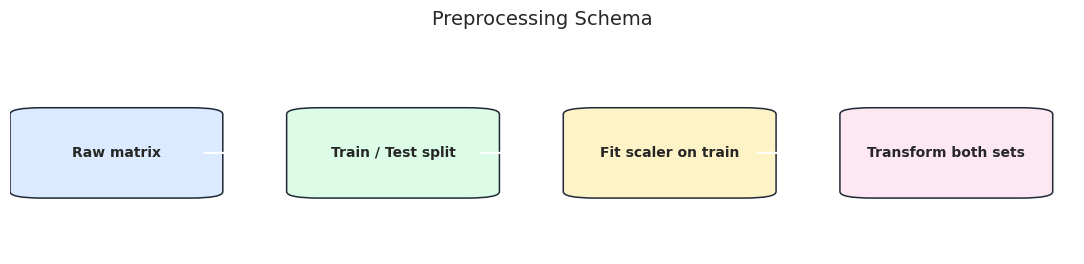

In [21]:
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")

blocks = [
    ("Raw matrix", 0.02, "#DBEAFE"),
    ("Train / Test split", 0.28, "#DCFCE7"),
    ("Fit scaler on train", 0.54, "#FEF3C7"),
    ("Transform both sets", 0.80, "#FCE7F3"),
]

for label, x0, color in blocks:
    rect = FancyBboxPatch(
        (x0, 0.28),
        0.16,
        0.38,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        linewidth=1.1,
        edgecolor="#1F2937",
        facecolor=color,
    )
    ax.add_patch(rect)
    ax.text(x0 + 0.08, 0.47, label, ha="center", va="center", fontsize=10, weight="bold")

for (_, x0, _), (_, x1, _) in zip(blocks[:-1], blocks[1:]):
    ax.annotate("", xy=(x1 - 0.02, 0.47), xytext=(x0 + 0.16, 0.47), arrowprops=dict(arrowstyle="->", lw=1.5))

ax.set_title("Preprocessing Schema", fontsize=14, pad=10)
plt.tight_layout()
plt.show()


**Preprocessing note.** Standardization is fitted on the training set only and then applied to the test set to prevent information leakage.


## 4. Logistic Regression Model


In [22]:
logistic_pipeline = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                solver="liblinear",
                C=1.0,
                class_weight="balanced",
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

logistic_pipeline.fit(X_train, y_train)
y_pred = logistic_pipeline.predict(X_test)
y_proba = logistic_pipeline.predict_proba(X_test)[:, 1]


In [23]:
all_feature_metrics = {
    "feature_set": "All features",
    "n_features": X_train.shape[1],
    "accuracy": accuracy_score(y_test, y_pred),
    "auc": roc_auc_score(y_test, y_proba),
}

display(pd.DataFrame([all_feature_metrics]))
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[negative_label, positive_label],
        digits=4,
    )
)


,feature_set,n_features,accuracy,auc
0,All features,60,1.0,1.0


              precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        81
     tumoral     1.0000    1.0000    1.0000        80

    accuracy                         1.0000       161
   macro avg     1.0000    1.0000    1.0000       161
weighted avg     1.0000    1.0000    1.0000       161



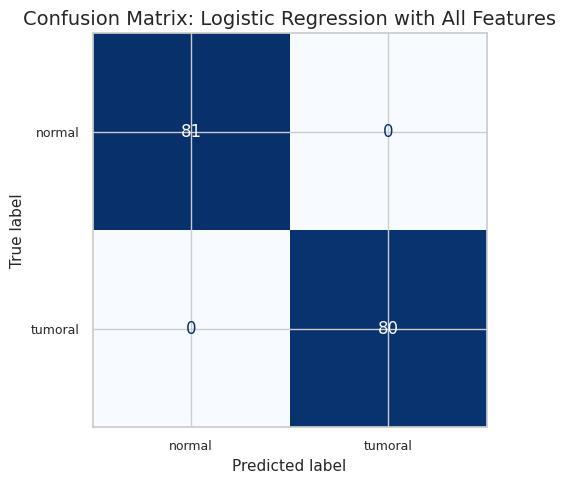

In [24]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=[negative_label, positive_label]).plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False,
)
ax.set_title("Confusion Matrix: Logistic Regression with All Features")
plt.tight_layout()
plt.show()


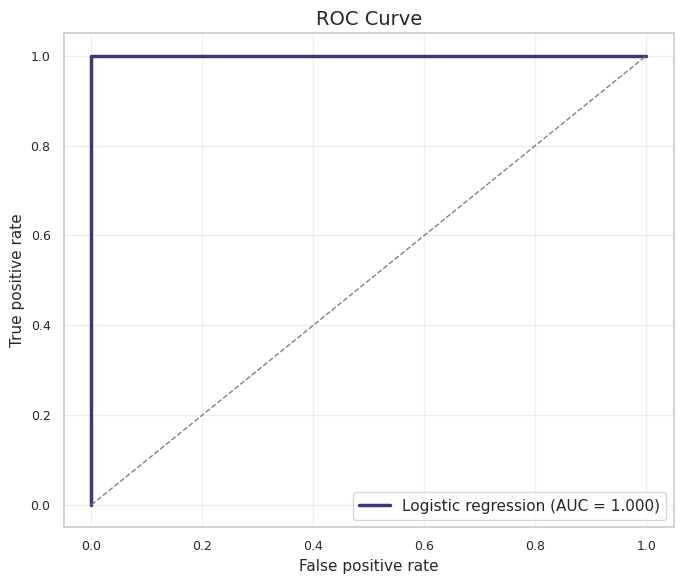

In [25]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, linewidth=2.5, label=f"Logistic regression (AUC = {auc_score:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
ax.set_title("ROC Curve")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


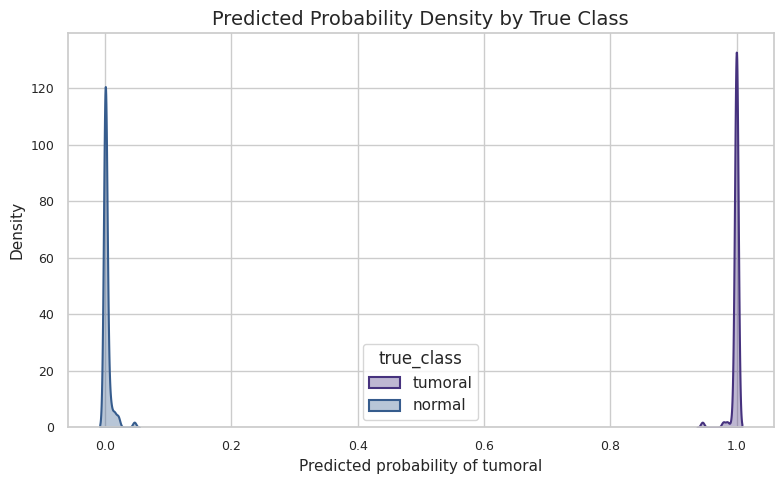

In [26]:
probability_frame = pd.DataFrame(
    {
        "probability": y_proba,
        "true_class": np.where(y_test == 1, positive_label, negative_label),
    }
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.kdeplot(
    data=probability_frame,
    x="probability",
    hue="true_class",
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=1.5,
    ax=ax,
)
ax.set_title("Predicted Probability Density by True Class")
ax.set_xlabel(f"Predicted probability of {positive_label}")
ax.set_ylabel("Density")
plt.tight_layout()
plt.show()


In [27]:
display(
    Markdown(
        f"**Performance interpretation.** The all-feature logistic model achieved "
        f"accuracy = `{all_feature_metrics['accuracy']:.3f}` and AUC = `{all_feature_metrics['auc']:.3f}` "
        f"on the stratified holdout set."
    )
)


**Performance interpretation.** The all-feature logistic model achieved accuracy = `1.000` and AUC = `1.000` on the stratified holdout set.

## 5. Feature Importance Analysis


In [28]:
fitted_model = logistic_pipeline.named_steps["model"]
coefficients = fitted_model.coef_.ravel()

coefficient_table = (
    pd.DataFrame(
        {
            "feature": feature_cols,
            "coefficient": coefficients,
            "absolute_importance": np.abs(coefficients),
        }
    )
    .sort_values("absolute_importance", ascending=False)
    .reset_index(drop=True)
)

display(coefficient_table.head(20))


,feature,coefficient,absolute_importance
0,RNF43,0.927773,0.927773
1,SLC7A5,0.892360,0.892360
2,UGP2,-0.706640,0.706640
3,DAO,-0.695055,0.695055
4,NEURL1B,-0.626603,0.626603
5,NCAPH,0.593606,0.593606
6,DDIT4,0.499599,0.499599
7,CLIC5,-0.446503,0.446503
8,NIBAN1,-0.444253,0.444253
9,DHRS11,-0.443762,0.443762


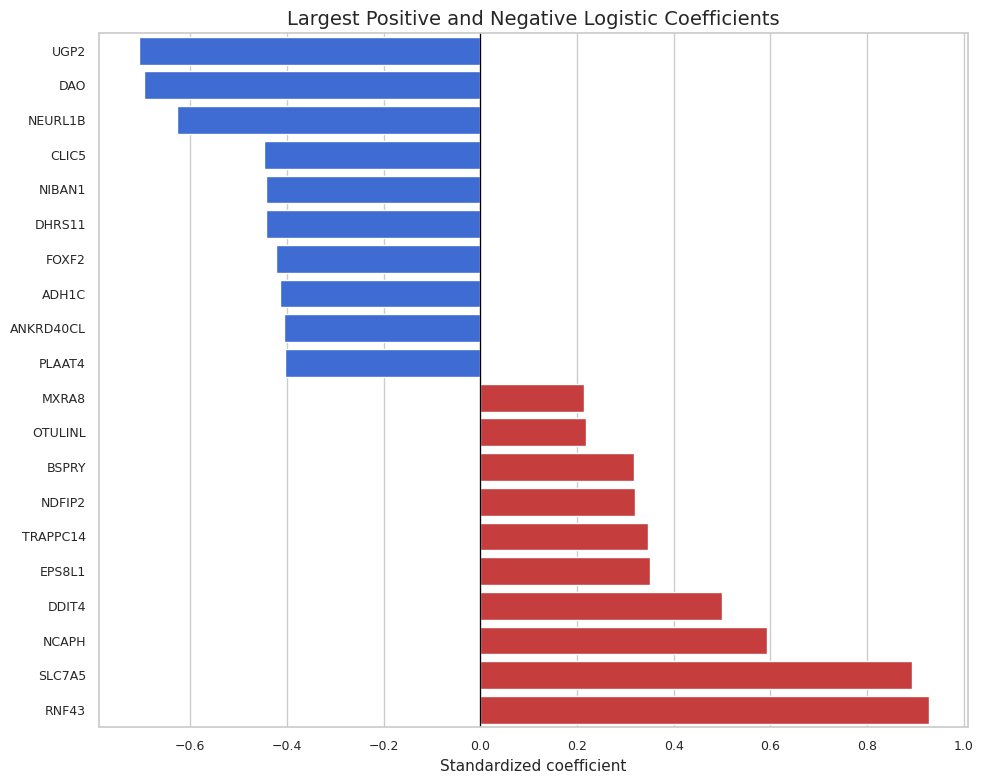

In [29]:
signed_top = pd.concat(
    [
        coefficient_table.sort_values("coefficient", ascending=False).head(10),
        coefficient_table.sort_values("coefficient", ascending=True).head(10),
    ]
).sort_values("coefficient")
signed_top["direction"] = np.where(signed_top["coefficient"] > 0, "Positive", "Negative")

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(
    data=signed_top,
    y="feature",
    x="coefficient",
    hue="direction",
    dodge=False,
    palette={"Positive": "#DC2626", "Negative": "#2563EB"},
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.9)
ax.set_title("Largest Positive and Negative Logistic Coefficients")
ax.set_xlabel("Standardized coefficient")
ax.set_ylabel("")
ax.legend_.remove()
plt.tight_layout()
plt.show()


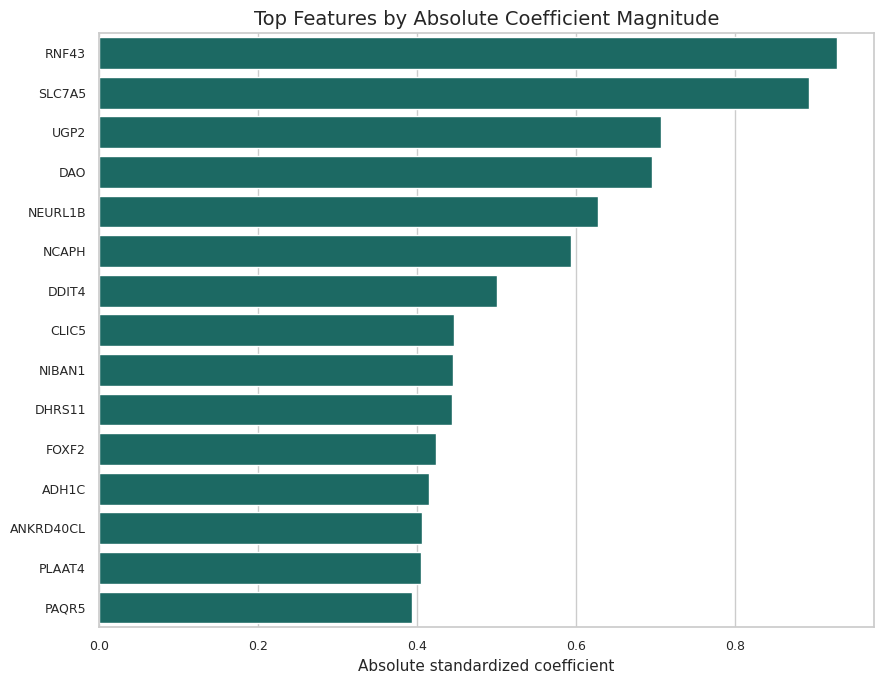

In [30]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(
    data=coefficient_table.head(15),
    y="feature",
    x="absolute_importance",
    color="#0F766E",
    ax=ax,
)
ax.set_title("Top Features by Absolute Coefficient Magnitude")
ax.set_xlabel("Absolute standardized coefficient")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


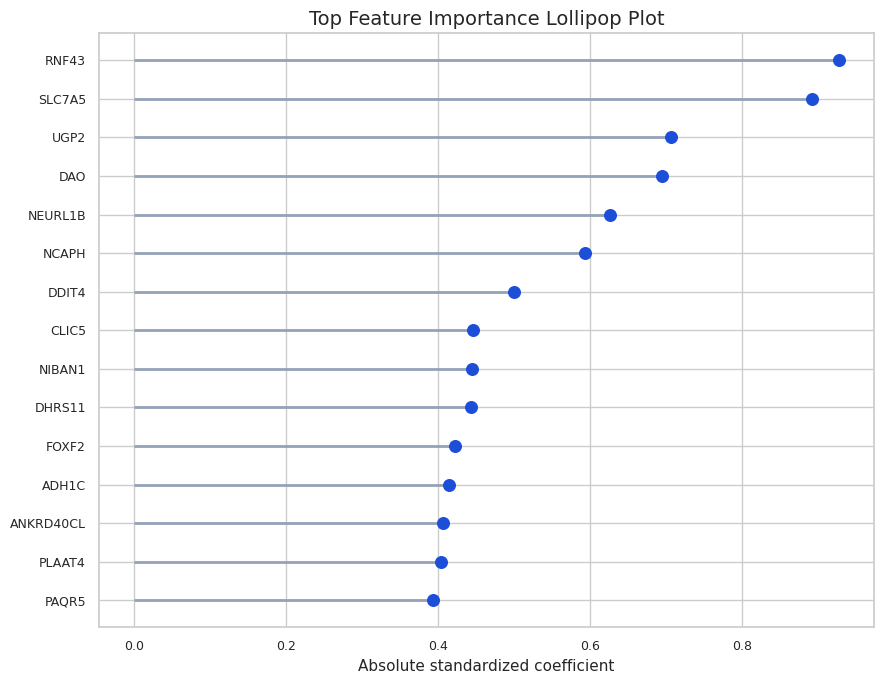

In [31]:
top_abs = coefficient_table.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 7))
ax.hlines(top_abs["feature"], 0, top_abs["absolute_importance"], color="#94A3B8", linewidth=2)
ax.scatter(top_abs["absolute_importance"], top_abs["feature"], color="#1D4ED8", s=70, zorder=3)
ax.set_title("Top Feature Importance Lollipop Plot")
ax.set_xlabel("Absolute standardized coefficient")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


In [32]:
positive_features = coefficient_table.sort_values("coefficient", ascending=False).head(5)["feature"].tolist()
negative_features = coefficient_table.sort_values("coefficient", ascending=True).head(5)["feature"].tolist()

display(
    Markdown(
        "**Coefficient interpretation.** Positive coefficients increase the log-odds of the positive "
        f"class (`{positive_label}`), while negative coefficients shift predictions toward `{negative_label}`. "
        f"The strongest positive features include `{', '.join(positive_features)}`; the strongest negative "
        f"features include `{', '.join(negative_features)}`."
    )
)


**Coefficient interpretation.** Positive coefficients increase the log-odds of the positive class (`tumoral`), while negative coefficients shift predictions toward `normal`. The strongest positive features include `RNF43, SLC7A5, NCAPH, DDIT4, EPS8L1`; the strongest negative features include `UGP2, DAO, NEURL1B, CLIC5, NIBAN1`.

## 6. Feature Selection


In [33]:
selected_feature_sets = {
    "Top 3": coefficient_table.head(3)["feature"].tolist(),
    "Top 5": coefficient_table.head(5)["feature"].tolist(),
    "Top 10": coefficient_table.head(10)["feature"].tolist(),
}

for name, features in selected_feature_sets.items():
    print(f"{name}: {features}")


Top 3: ['RNF43', 'SLC7A5', 'UGP2']
Top 5: ['RNF43', 'SLC7A5', 'UGP2', 'DAO', 'NEURL1B']
Top 10: ['RNF43', 'SLC7A5', 'UGP2', 'DAO', 'NEURL1B', 'NCAPH', 'DDIT4', 'CLIC5', 'NIBAN1', 'DHRS11']


In [34]:
reduced_shapes = pd.DataFrame(
    {
        "feature_set": list(selected_feature_sets.keys()),
        "n_features": [len(features) for features in selected_feature_sets.values()],
        "train_shape": [X_train[features].shape for features in selected_feature_sets.values()],
        "test_shape": [X_test[features].shape for features in selected_feature_sets.values()],
    }
)
display(reduced_shapes)


,feature_set,n_features,train_shape,test_shape
0,Top 3,3,"(643, 3)","(161, 3)"
1,Top 5,5,"(643, 5)","(161, 5)"
2,Top 10,10,"(643, 10)","(161, 10)"


## 7. Retraining on Selected Features


In [35]:
def fit_evaluate_logistic(feature_names, label):
    pipeline = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    solver="liblinear",
                    C=1.0,
                    class_weight="balanced",
                    max_iter=5000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )
    start = time.perf_counter()
    pipeline.fit(X_train[feature_names], y_train)
    fit_time = time.perf_counter() - start

    predictions = pipeline.predict(X_test[feature_names])
    probabilities = pipeline.predict_proba(X_test[feature_names])[:, 1]

    return {
        "feature_set": label,
        "n_features": len(feature_names),
        "accuracy": accuracy_score(y_test, predictions),
        "auc": roc_auc_score(y_test, probabilities),
        "fit_time_seconds": fit_time,
    }

comparison_rows = [all_feature_metrics | {"fit_time_seconds": np.nan}]
comparison_rows.extend(
    fit_evaluate_logistic(features, label)
    for label, features in selected_feature_sets.items()
)

performance_comparison = pd.DataFrame(comparison_rows)
display(performance_comparison)


,feature_set,n_features,accuracy,auc,fit_time_seconds
0,All features,60,1.000000,1.000000,NaN
1,Top 3,3,0.981366,0.999383,0.007347
2,Top 5,5,1.000000,1.000000,0.004898
3,Top 10,10,1.000000,1.000000,0.007478


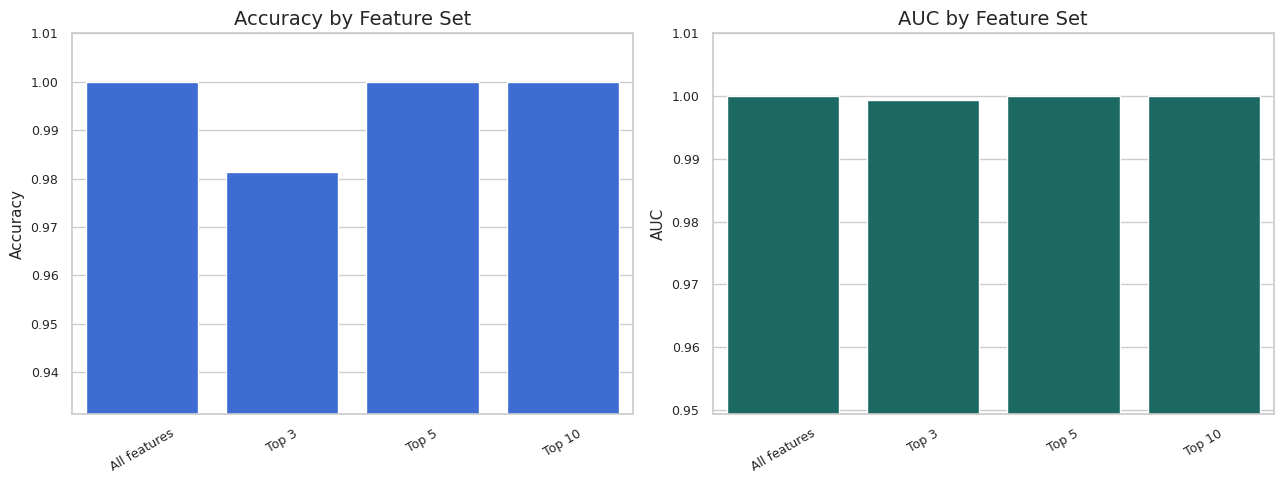

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)

sns.barplot(data=performance_comparison, x="feature_set", y="accuracy", ax=axes[0], color="#2563EB")
axes[0].set_title("Accuracy by Feature Set")
axes[0].set_ylim(max(0, performance_comparison["accuracy"].min() - 0.05), 1.01)
axes[0].set_xlabel("")
axes[0].set_ylabel("Accuracy")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=performance_comparison, x="feature_set", y="auc", ax=axes[1], color="#0F766E")
axes[1].set_title("AUC by Feature Set")
axes[1].set_ylim(max(0, performance_comparison["auc"].min() - 0.05), 1.01)
axes[1].set_xlabel("")
axes[1].set_ylabel("AUC")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


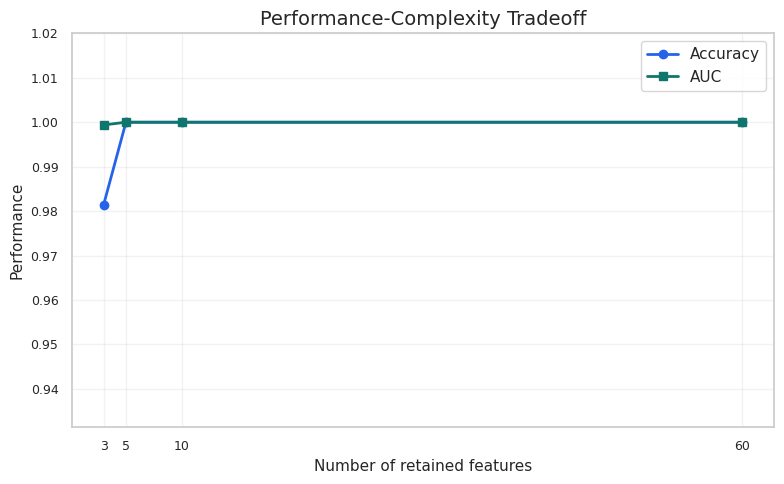

In [37]:
ordered = performance_comparison.sort_values("n_features")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ordered["n_features"], ordered["accuracy"], marker="o", linewidth=2, color="#2563EB", label="Accuracy")
ax.plot(ordered["n_features"], ordered["auc"], marker="s", linewidth=2, color="#0F766E", label="AUC")
ax.set_xticks(ordered["n_features"])
ax.set_xlabel("Number of retained features")
ax.set_ylabel("Performance")
ax.set_ylim(max(0, min(ordered["accuracy"].min(), ordered["auc"].min()) - 0.05), 1.02)
ax.set_title("Performance-Complexity Tradeoff")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [38]:
best_reduced = performance_comparison.query("feature_set != 'All features'").sort_values(
    ["auc", "accuracy", "n_features"], ascending=[False, False, True]
).iloc[0]

display(
    Markdown(
        f"**Feature-selection interpretation.** The best reduced configuration was `{best_reduced.feature_set}` "
        f"with accuracy = `{best_reduced.accuracy:.3f}` and AUC = `{best_reduced.auc:.3f}`. "
        "Reduced models improve interpretability and can preserve predictive performance when dominant features "
        "capture most discriminative signal."
    )
)


**Feature-selection interpretation.** The best reduced configuration was `Top 5` with accuracy = `1.000` and AUC = `1.000`. Reduced models improve interpretability and can preserve predictive performance when dominant features capture most discriminative signal.

## 8. Correlation Analysis of Selected Features


In [39]:
selected_for_correlation = selected_feature_sets["Top 10"]
selected_corr = df[selected_for_correlation].corr()
display(selected_corr)


,RNF43,SLC7A5,UGP2,DAO,NEURL1B,NCAPH,DDIT4,CLIC5,NIBAN1,DHRS11
RNF43,1.000000,0.642110,-0.614690,-0.441998,-0.476220,0.498947,0.416879,-0.460961,-0.546538,-0.345203
SLC7A5,0.642110,1.000000,-0.777432,-0.613886,-0.637259,0.619604,0.579702,-0.662781,-0.539186,-0.547042
UGP2,-0.614690,-0.777432,1.000000,0.676845,0.709623,-0.493236,-0.566576,0.700540,0.498796,0.615602
DAO,-0.441998,-0.613886,0.676845,1.000000,0.661945,-0.511249,-0.454916,0.566719,0.348857,0.653149
NEURL1B,-0.476220,-0.637259,0.709623,0.661945,1.000000,-0.520656,-0.557838,0.589434,0.478234,0.579772
NCAPH,0.498947,0.619604,-0.493236,-0.511249,-0.520656,1.000000,0.473928,-0.399671,-0.503124,-0.374159
DDIT4,0.416879,0.579702,-0.566576,-0.454916,-0.557838,0.473928,1.000000,-0.479899,-0.370001,-0.442893
CLIC5,-0.460961,-0.662781,0.700540,0.566719,0.589434,-0.399671,-0.479899,1.000000,0.378919,0.574931
NIBAN1,-0.546538,-0.539186,0.498796,0.348857,0.478234,-0.503124,-0.370001,0.378919,1.000000,0.272243
DHRS11,-0.345203,-0.547042,0.615602,0.653149,0.579772,-0.374159,-0.442893,0.574931,0.272243,1.000000


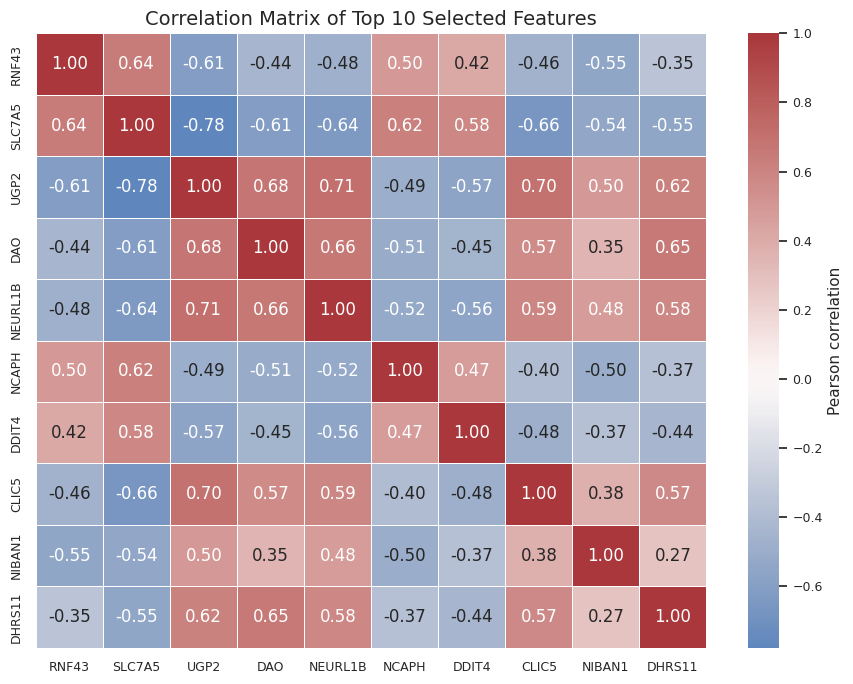

In [40]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    selected_corr,
    cmap="vlag",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax,
)
ax.set_title("Correlation Matrix of Top 10 Selected Features")
plt.tight_layout()
plt.show()


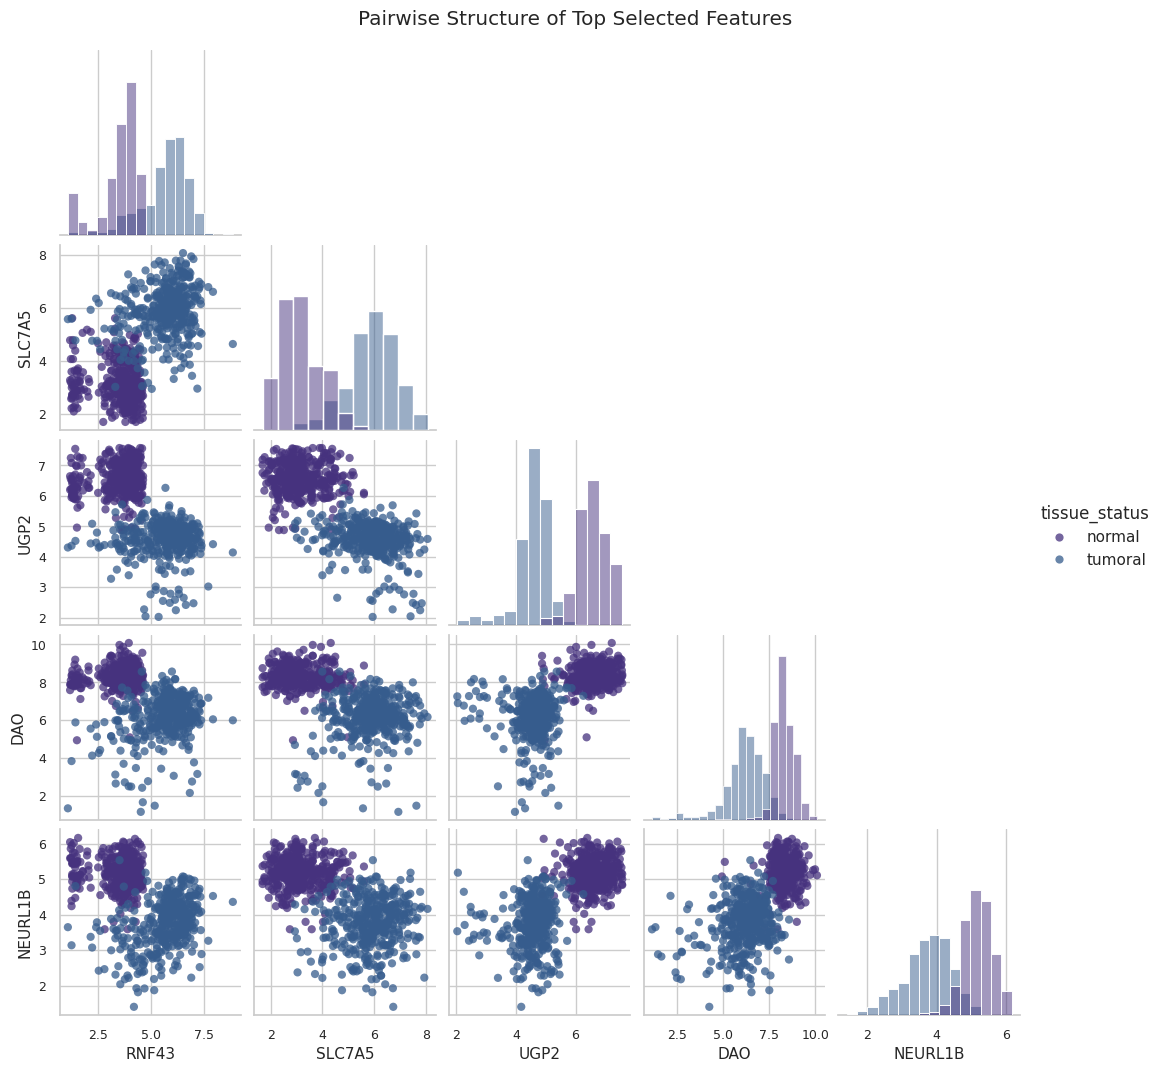

In [41]:
pairplot_features = selected_feature_sets["Top 5"]
pairplot_df = df[pairplot_features + [target_col]].copy()

grid = sns.pairplot(
    pairplot_df,
    hue=target_col,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.75, "s": 35, "edgecolor": "none"},
    height=2.1,
)
grid.fig.suptitle("Pairwise Structure of Top Selected Features", y=1.02)
plt.show()


**Correlation interpretation.** Correlated selected genes may encode overlapping biological signal. Redundancy should be considered when interpreting coefficients as independent effects.


## 9. Final Analytical Discussion


The logistic regression model provides a transparent linear decision function on standardized gene-expression features. Coefficient magnitudes identify variables that most strongly shift the log-odds of tumoral classification, while sign direction differentiates tumor-associated and normal-associated expression patterns. Feature selection based on absolute standardized coefficients reduces dimensionality and concentrates interpretation on a compact biomarker subset.

From a healthcare perspective, high discriminatory performance suggests that the measured gene-expression profile contains strong tissue-status signal. However, clinical interpretation requires external validation, biological replication, calibration assessment, and evaluation under independent cohort shift. Coefficient importance should not be interpreted as causal evidence.


## 10. Conclusion


This project implemented a reproducible logistic-regression pipeline for colon cancer tissue classification. The analysis included structured inspection, EDA, standardized preprocessing, all-feature modeling, coefficient-based feature ranking, reduced-feature retraining, and correlation assessment of selected predictors. The final workflow balances predictive evaluation with interpretable feature-level analysis.
